# PyTorch: Autoencoder convolucional Fashion-MNIST

## Refs.

* https://pytorch.org/tutorials/beginner/basics/optimization_tutorial.html
* https://github.com/zalandoresearch/fashion-mnist
* https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html
* https://pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html
* V. Dumoulin y F. Visin, *A guide to convolution arithmetic for deep learning*, https://arxiv.org/abs/1603.07285

## **Ejercicio 1)** Preparando el entorno

**1)** De ser necesario, instale **PyTorch** y **torchvision** (en Google Colab ya vienen instalados):

    !pip3 install torch torchvision

**2)** Importe `matplotlib.pyplot`, `numpy`, `torch`, `torch.nn`, las clases `Dataset` y `DataLoader` de `torch.utils.data`, y los módulos `datasets` y `transforms` de `torchvision`.

**3)** Determine en qué dispositivo (`device`) va a trabajar: una **CPU** o una **GPU**.
Fije las semillas de los generadores de números aleatorios para que los resultados sean reproducibles.

In [1]:
# 1.1)
#!pip3 install torch torchvision

In [2]:
# 1.2)
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms

In [3]:
# 1.3)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(0)
np.random.seed(0)
print("device =", device)

device = cuda


## **Ejercicio 2)** Bajando y jugando con el dataset **Fashion-MNIST**

**1)** Baje y transforme los conjuntos de entrenamiento y validación de Fashion-MNIST, de modo que cada imagen sea un tensor de dimensiones $(1,28,28)$ con valores en el intervalo $[0,1]$.

**IMPORTANTE:** Más adelante, la salida del autoencoder pasará por una `Sigmoid`, que toma valores en $(0,1)$.
Por lo tanto, **no** normalice las imágenes al intervalo $[-1,1]$ (p.ej. con `transforms.Normalize((0.5,),(0.5,))`): de hacerlo, el autoencoder no podría reconstruir los píxeles negativos.

**2)** Grafique un mosaico de $3\times 3$ imágenes de Fashion-MNIST, cada una titulada con el nombre de su respectiva clase.

In [4]:
# 2.1)
# ToTensor() convierte la imagen PIL a un tensor (1,28,28) con valores en [0,1]
transform = transforms.ToTensor()
train_set_orig = datasets.FashionMNIST('MNIST_data/', download=True, train=True,  transform=transform)
valid_set_orig = datasets.FashionMNIST('MNIST_data/', download=True, train=False, transform=transform)
print(len(train_set_orig), len(valid_set_orig))
image, label = train_set_orig[0]
print(image.shape, image.min().item(), image.max().item())

100%|██████████| 26.4M/26.4M [00:02<00:00, 13.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 204kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.80MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.4MB/s]

60000 10000
torch.Size([1, 28, 28]) 0.0 1.0


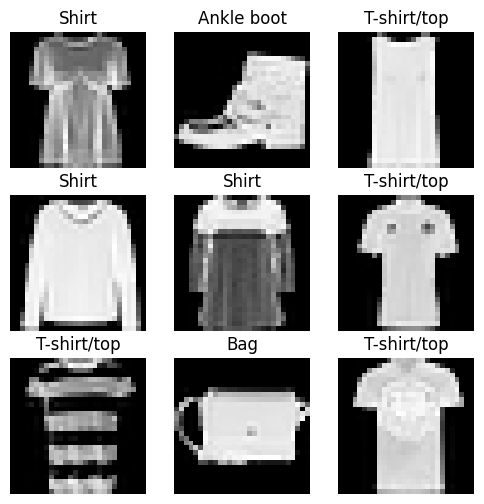

In [5]:
# 2.2)
labels_names = train_set_orig.classes # ['T-shirt/top', 'Trouser', ..., 'Ankle boot']
figure = plt.figure(figsize=(6,6))
rows, cols = 3, 3
for i in range(1, rows*cols+1):
    j = torch.randint(len(train_set_orig), size=(1,)).item()
    image, label = train_set_orig[j]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_names[label])
    plt.axis("off")
    plt.imshow(image.squeeze(), cmap="Greys_r")
plt.show()

## **Ejercicio 3)** Creando un `Dataset` personalizado

**1)** Con el fin de entrenar un autoencoder, defina una clase `CustomDataset` derivada de la clase `Dataset`, cuyo método `__getitem__(self,i)` retorne el par `(input,output)`, donde tanto `input` como `output` son iguales a la $i$-ésima imagen del dataset original (en vez del par `(imagen,label)`).

**2)** Utilice dicha clase para transformar los conjuntos de entrenamiento y validación de Fashion-MNIST, pensados para clasificación, en conjuntos pensados para entrenar un autoencoder.

In [6]:
# 3.1)
class CustomDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset
    def __len__(self):
        return len(self.dataset)
    def __getitem__(self, i):
        image, label = self.dataset[i]
        return image, image # input = output = imagen

In [7]:
# 3.2)
train_set = CustomDataset(train_set_orig)
valid_set = CustomDataset(valid_set_orig)

## **Ejercicio 4)** Red neuronal autoencoder convolucional

Para una entrada de tamaño $H_{in}$ (por dimensión espacial), las capas `Conv2d` (y `MaxPool2d`) y `ConvTranspose2d` producen salidas de tamaño
$$
H_{out}^{\rm conv} = \left\lfloor \frac{H_{in} + 2\,{\rm padding} - {\rm kernel}}{\rm stride} \right\rfloor + 1,
\qquad
H_{out}^{\rm convT} = (H_{in}-1)\,{\rm stride} - 2\,{\rm padding} + {\rm kernel} + {\rm output\_padding},
$$
respectivamente (con `dilation=1`).
La convolución transpuesta **no** es la inversa de la convolución: es la transpuesta (adjunta) de la transformación lineal que define una convolución con los mismos parámetros.
Por eso mapea tamaños "chicos" en tamaños "grandes", invirtiendo las *dimensiones* (no los valores), lo que la hace útil como capa de "des-convolución" o *upsampling* aprendible.

**1)** Usando las fórmulas de arriba, verifique que una `Conv2d` con kernel $3$ mapea $28\to 26$, que una `MaxPool2d` con kernel $2$ mapea $26\to 13$, y que una `ConvTranspose2d` con kernel $6$, stride $2$ y padding $1$ mapea $13\to 28$.

**2)** Defina una red neuronal *autoencoder convolucional* constituida por los siguientes bloques:

1. **Encoder** convolucional:
   * Una capa `Conv2d` que mapea una entrada con $1$ canal y dimensiones $(28,28)$ a una salida con $16$ canales y dimensiones $(26,26)$. Utilice un kernel de dimensiones $(3,3)$ y el resto de los parámetros en sus valores por defecto.
   * Una capa `ReLU`.
   * Una capa `MaxPool2d` con un kernel de dimensiones $(2,2)$, de modo que la salida resultante tenga dimensiones $(16,13,13)$.
   * Una capa `Dropout` con probabilidad $p$.

2. **Cuello de botella** (*bottleneck*) lineal:
   * Una capa `Flatten` que transforma una entrada de dimensiones $(16,13,13)$ en un vector de dimensión $16\times 13\times 13 = 2704$.
   * Una capa `Linear` que mapea el vector de dimensión $2704$ a un vector de dimensión $n$ (con $n\ll 784$, por ejemplo $n=128$), que representa la *codificación latente* comprimida.
   * Una capa `ReLU`.
   * Una capa `Linear` que mapea de nuevo el vector de dimensión $n$ a un vector de dimensión $2704$.
   * Una capa `ReLU`.

3. **Decoder** convolucional transpuesto:
   * Una capa `Unflatten` que mapea el vector de dimensión $2704$ a un tensor de $16$ canales con dimensiones $(13,13)$.
   * Una capa `ConvTranspose2d` que mapea $16$ canales de dimensiones $(13,13)$ a $1$ canal de dimensiones $(28,28)$. Utilice un kernel de dimensiones $(6,6)$, un stride de $(2,2)$ y un padding de $(1,1)$.
   * Una capa `Sigmoid`, para asegurar que las salidas se encuentren en el rango $[0,1]$, al igual que las imágenes de entrada.

Verifique, con un tensor de entrada aleatorio de dimensiones $(1,1,28,28)$, que la salida tiene las mismas dimensiones que la entrada.

**3)** Grafique, a modo de comparación, algunas imágenes de entrada y sus correspondientes reconstrucciones obtenidas con el modelo **sin entrenar**, con una probabilidad de *dropout* $p=0.2$.

In [8]:
# 4.1)
def conv_out(H, kernel, stride=1, padding=0):
    return (H + 2*padding - kernel)//stride + 1

def convT_out(H, kernel, stride=1, padding=0, output_padding=0):
    return (H - 1)*stride - 2*padding + kernel + output_padding

print("Conv2d(k=3):            28 ->", conv_out(28, kernel=3))
print("MaxPool2d(k=2):         26 ->", conv_out(26, kernel=2, stride=2))
print("ConvTranspose2d(6,2,1): 13 ->", convT_out(13, kernel=6, stride=2, padding=1))

Conv2d(k=3):            28 -> 26
MaxPool2d(k=2):         26 -> 13
ConvTranspose2d(6,2,1): 13 -> 28


In [9]:
# 4.2)
class Autoencoder(nn.Module):
    def __init__(self, p=0.2, n=128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3), # (1,28,28) -> (16,26,26)
            nn.ReLU(),
            nn.MaxPool2d(2),                 # (16,26,26) -> (16,13,13)
            nn.Dropout(p),
        )
        self.bottleneck = nn.Sequential(
            nn.Flatten(),                    # (16,13,13) -> 2704
            nn.Linear(16*13*13, n),          # 2704 -> n (código latente)
            nn.ReLU(),
            nn.Linear(n, 16*13*13),          # n -> 2704
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (16, 13, 13)),   # 2704 -> (16,13,13)
            nn.ConvTranspose2d(16, 1, kernel_size=6, stride=2, padding=1), # (16,13,13) -> (1,28,28)
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.decoder(self.bottleneck(self.encoder(x)))

model = Autoencoder(p=0.2)
x = torch.randn(1, 1, 28, 28) # batch de tamaño 1
print("input size: ", x.size())
print("output size:", model(x).size())
print("numero de parametros: ", sum(p.numel() for p in model.parameters()))

input size:  torch.Size([1, 1, 28, 28])
output size: torch.Size([1, 1, 28, 28])
numero de parametros:  695793


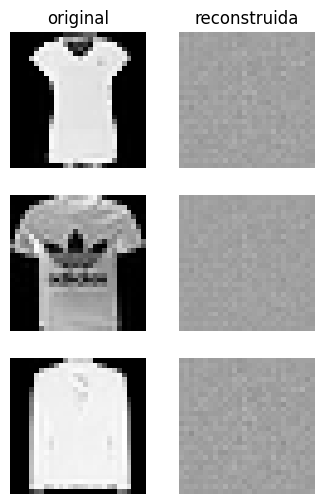

In [10]:
# 4.3)
def plot_reconstructions(model, dataset, n=3):
    # Grafica n imágenes elegidas al azar (izq.) y sus reconstrucciones (der.)
    model.eval() # desactiva el dropout
    device = next(model.parameters()).device
    figure = plt.figure(figsize=(4, 2*n))
    for row in range(n):
        j = torch.randint(len(dataset), size=(1,)).item()
        image, _ = dataset[j]
        with torch.no_grad():
            pred = model(image.unsqueeze(0).to(device)) # (1,28,28) -> (1,1,28,28)
        for col, (img, title) in enumerate([(image, "original"), (pred, "reconstruida")]):
            figure.add_subplot(n, 2, 2*row+col+1)
            if row == 0:
                plt.title(title)
            plt.axis("off")
            plt.imshow(img.squeeze().cpu().numpy(), cmap="Greys_r", vmin=0, vmax=1)
    plt.show()

plot_reconstructions(model, valid_set)

## **Ejercicio 5)** Entrenando el modelo

**1)** Implemente, en una función, un loop de entrenamiento que recorra los lotes (*batches*) y retorne la pérdida promedio sobre la época.

**2)** Implemente, en una función, un loop de validación que recorra los lotes y retorne la pérdida promedio.

**3)** Cree dos `DataLoader`s, `train_loader` y `valid_loader`, definidos sobre `train_set` y `valid_set`, respectivamente, que usen lotes de 100 ejemplos.

**4)** Cree una función de pérdida usando el **error cuadrático medio** (ECM).

**5)** Cree una instancia del modelo con dropout $p=0.2$ y cópiela al dispositivo de trabajo.

**6)** Cree un optimizador **ADAM** con un learning rate igual a $10^{-3}$.

**7)** Implemente un loop que itere sobre épocas de entrenamiento y validación, y que guarde en listas los siguientes valores del ECM:
*  promedio (*incorrecto*) sobre el conjunto de entrenamiento, calculado **durante** el proceso de entrenamiento sobre la época;
*  promedio (correcto) sobre el conjunto de entrenamiento, calculado **posteriormente** al entrenamiento sobre la época;
*  promedio (correcto) sobre el conjunto de validación, calculado **posteriormente** al entrenamiento sobre la época.

¿Por qué el primero de estos promedios es "incorrecto"?

**IMPORTANTE:** No olvide copiar los lotes al dispositivo de trabajo.

**8)** Entrene y valide el modelo.

**9)** Use las listas del inciso **7)** para graficar, en función de las **épocas**, el ECM de **entrenamiento** y de **validación**.
Discuta y comente: ¿cuál es el número óptimo de épocas de entrenamiento?

**10)** Grafique, comparativamente, algunas imágenes del conjunto de validación y sus reconstrucciones obtenidas con el modelo entrenado.

**11)** Repita para otras elecciones de los hiperparámetros, tales como el optimizador (p.ej. **SGD**), el **learning rate**, el tamaño de los **lotes**, el **dropout**, la dimensión $n$ del **código latente**, y **capas convolucionales** y **convolucionales transpuestas** de otros tamaños.
En particular, pruebe eliminando, adecuadamente, el **cuello de botella lineal**.
¿Qué valores de estos hiperparámetros considera los más convenientes? ¿Por qué?

In [11]:
# 5.1)
def train_loop(dataloader, model, loss_fn, optimizer, verbose=False):
    model.train() # activa el dropout
    device = next(model.parameters()).device
    num_batches = len(dataloader)
    sum_loss, sum_samples = 0.0, 0
    for i, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)
        # Predicción y pérdida
        pred = model(X)
        loss = loss_fn(pred, y)
        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # Acumulamos la pérdida (loss es el promedio sobre el lote)
        sum_loss += loss.item()*len(X)
        sum_samples += len(X)
        if verbose and i % max(1, num_batches//10) == 0:
            print(f"  batch={i:>4d}/{num_batches} avrg_loss={sum_loss/sum_samples:.6f}")
    return sum_loss/sum_samples

In [12]:
# 5.2)
def eval_loop(dataloader, model, loss_fn):
    model.eval() # desactiva el dropout
    device = next(model.parameters()).device
    sum_loss, sum_samples = 0.0, 0
    with torch.no_grad(): # no hace falta calcular gradientes
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            sum_loss += loss_fn(model(X), y).item()*len(X)
            sum_samples += len(X)
    return sum_loss/sum_samples

In [13]:
# 5.3)
batch_size = 100
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=batch_size, shuffle=False) # no hace falta mezclar para validar
print("num_train_batches =", len(train_loader))
print("num_valid_batches =", len(valid_loader))

num_train_batches = 600
num_valid_batches = 100


In [14]:
# 5.4)
loss_fn = nn.MSELoss()

In [15]:
# 5.5)
model = Autoencoder(p=0.2).to(device)

In [16]:
# 5.6)
# El optimizador se crea *después* de crear el modelo (y de moverlo al dispositivo),
# ya que recibe una referencia a sus parámetros.
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [17]:
# 5.7)
def fit(model, optimizer, train_loader, valid_loader, loss_fn, num_epochs, eval_train=True, verbose=True):
    history = {"train_incorrecta": [], "train": [], "valid": []}
    for epoch in range(1, num_epochs+1):
        history["train_incorrecta"].append(train_loop(train_loader, model, loss_fn, optimizer))
        if eval_train: # duplica el costo por época, opcional
            history["train"].append(eval_loop(train_loader, model, loss_fn))
        history["valid"].append(eval_loop(valid_loader, model, loss_fn))
        if verbose:
            print(f"epoch={epoch:>3d}  " + "  ".join(f"{k}={v[-1]:.6f}" for k, v in history.items() if v))
    return history

**Respuesta 5.7)** El promedio calculado durante `train_loop` es "incorrecto" por dos motivos: (i) cada lote se evalúa con un modelo distinto, ya que los parámetros se actualizan después de cada lote (los primeros lotes de la época se evalúan con un modelo "peor" que el obtenido al final de la época); (ii) se evalúa con el *dropout* activo (`model.train()`), es decir, con una red "ruidosa" distinta a la que se usa para predecir (`model.eval()`). Por ambos motivos, suele sobreestimar la pérdida de entrenamiento del modelo obtenido al final de la época.

In [18]:
# 5.8)
num_epochs = 30
history = fit(model, optimizer, train_loader, valid_loader, loss_fn, num_epochs)

epoch=  1  train_incorrecta=0.025769  train=0.014956  valid=0.015037
epoch=  2  train_incorrecta=0.013780  train=0.011751  valid=0.011854
epoch=  3  train_incorrecta=0.011884  train=0.010421  valid=0.010533
epoch=  4  train_incorrecta=0.010885  train=0.009630  valid=0.009755
epoch=  5  train_incorrecta=0.010298  train=0.009245  valid=0.009370
epoch=  6  train_incorrecta=0.009908  train=0.008863  valid=0.008993
epoch=  7  train_incorrecta=0.009630  train=0.008689  valid=0.008828
epoch=  8  train_incorrecta=0.009392  train=0.008499  valid=0.008646
epoch=  9  train_incorrecta=0.009219  train=0.008277  valid=0.008428
epoch= 10  train_incorrecta=0.009056  train=0.008177  valid=0.008334
epoch= 11  train_incorrecta=0.008926  train=0.008017  valid=0.008175
epoch= 12  train_incorrecta=0.008823  train=0.007919  valid=0.008079
epoch= 13  train_incorrecta=0.008732  train=0.007918  valid=0.008082
epoch= 14  train_incorrecta=0.008652  train=0.007778  valid=0.007950
epoch= 15  train_incorrecta=0.0085

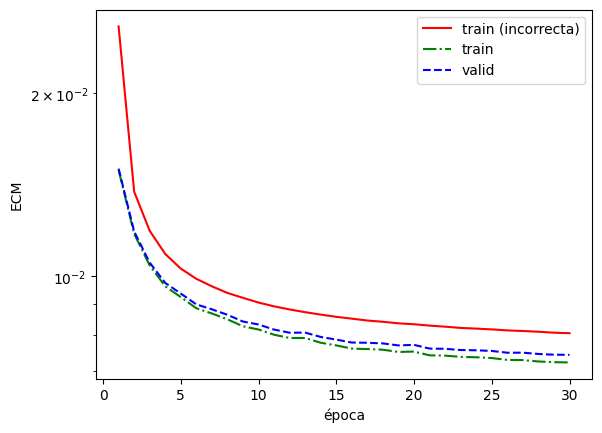

época con menor ECM de validación: 30


In [19]:
# 5.9)
def plot_history(history, title=""):
    epochs = range(1, len(history["valid"])+1)
    plt.plot(epochs, history["train_incorrecta"], label="train (incorrecta)", linestyle='-',  c='red')
    if history["train"]:
        plt.plot(epochs, history["train"],            label="train",              linestyle='-.', c='green')
    plt.plot(epochs, history["valid"],            label="valid",              linestyle='--', c='blue')
    plt.xlabel('época')
    plt.ylabel('ECM')
    plt.yscale('log')
    plt.title(title)
    plt.legend()
    plt.show()

plot_history(history)
print("época con menor ECM de validación:", int(np.argmin(history["valid"]))+1)

**Respuesta 5.9)**

Las curvas de entrenamiento y validación (correctas) prácticamente se superponen: el ECM de validación es sólo $\sim 3\%$ mayor que el de entrenamiento (p.ej. $0.00755$ vs $0.00733$ en la época 30). Es decir, en 30 épocas **no se observa sobreajuste**: ambas curvas siguen decreciendo, y el mínimo del ECM de validación se alcanza prácticamente en la última época. Por lo tanto, el número óptimo de épocas es $\gtrsim 30$, aunque con rendimientos decrecientes: entre las épocas 10 y 30 el ECM de validación baja sólo $\sim 11\%$ ($0.0085 \to 0.0075$), mientras que en las primeras 10 épocas baja casi a la mitad. En la práctica conviene usar *early stopping*: entrenar mientras el ECM de validación siga disminuyendo apreciablemente y quedarse con el modelo de menor ECM de validación.

Notar también que la curva "incorrecta" queda siempre por encima de la correcta, por los motivos discutidos en la respuesta 5.7.

En el inciso 5.10 se observa que las reconstrucciones conservan la forma global de cada prenda, pero son borrosas y pierden los detalles finos (estampados, texturas, costuras): un código latente de dimensión $n = 128$ y una pérdida ECM favorecen reconstruir el "promedio" de los detalles.

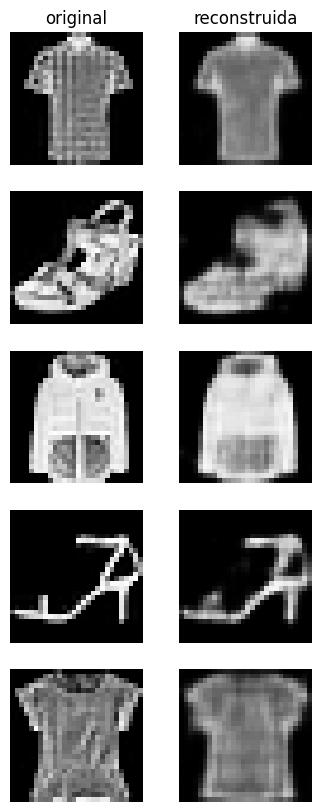

In [20]:
# 5.10)
plot_reconstructions(model, valid_set, n=5)

### 5.11) Exploración de hiperparámetros

Para que la exploración sea rápida, usamos menos épocas y no evaluamos sobre el conjunto de entrenamiento después de cada época.
Además de `Autoencoder`, definimos dos arquitecturas alternativas:

* `AutoencoderSinLineal`: elimina el cuello de botella lineal, conectando directamente la salida del encoder $(16,13,13)$ con la `ConvTranspose2d`.
  Notar que, sin cuello de botella, el "código" tiene dimensión $2704 > 784$: la red no está obligada a comprimir la información.
* `AutoencoderProfundo`: usa dos capas convolucionales con stride $2$ (en vez de `MaxPool2d`), $(1,28,28)\to(16,14,14)\to(32,7,7)$, un cuello de botella lineal de dimensión $n$, y dos capas convolucionales transpuestas que invierten las dimensiones, $(32,7,7)\to(16,14,14)\to(1,28,28)$.
  Aquí se necesita `output_padding=1`: con stride 2, tanto $14$ como $13$ se mapean a $7$, y `output_padding` desambigua el tamaño de salida de la convolución transpuesta.

In [23]:
# 5.11)
class AutoencoderSinLineal(nn.Module):
    def __init__(self, p=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3), # (1,28,28) -> (16,26,26)
            nn.ReLU(),
            nn.MaxPool2d(2),                 # (16,26,26) -> (16,13,13)
            nn.Dropout(p),
            nn.ConvTranspose2d(16, 1, kernel_size=6, stride=2, padding=1), # (16,13,13) -> (1,28,28)
            nn.Sigmoid(),
        )
    def forward(self, x):
        return self.net(x)

class AutoencoderProfundo(nn.Module):
    def __init__(self, p=0.2, n=128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),  # (1,28,28) -> (16,14,14)
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1), # (16,14,14) -> (32,7,7)
            nn.ReLU(),
            nn.Dropout(p),
            nn.Flatten(),
            nn.Linear(32*7*7, n),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(n, 32*7*7),
            nn.ReLU(),
            nn.Unflatten(1, (32, 7, 7)),
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1), # (32,7,7) -> (16,14,14)
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),  # (16,14,14) -> (1,28,28)
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

for M in [AutoencoderSinLineal, AutoencoderProfundo]:
    print(M.__name__, M()(torch.randn(1, 1, 28, 28)).shape)

AutoencoderSinLineal torch.Size([1, 1, 28, 28])
AutoencoderProfundo torch.Size([1, 1, 28, 28])


In [24]:
def run_experiment(arch=Autoencoder, arch_kwargs={}, opt="adam", lr=1e-3, batch_size=100, num_epochs=10):
    torch.manual_seed(0)
    model = arch(**arch_kwargs).to(device)
    if opt == "adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    else:
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9 if opt == "sgd-momentum" else 0.0)
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
    valid_loader = DataLoader(valid_set, batch_size=batch_size, shuffle=False)
    history = fit(model, optimizer, train_loader, valid_loader, loss_fn, num_epochs, eval_train=False, verbose=False)
    return model, history
experiments = {
    "base: adam lr=1e-3 bs=100 p=0.2 n=128": dict(),
    # optimizador y learning rate
    "sgd lr=1e-3":               dict(opt="sgd",          lr=1e-3),
    "sgd+momentum lr=1e-1":      dict(opt="sgd-momentum", lr=1e-1),
    "adam lr=1e-2":              dict(lr=1e-2),
    "adam lr=1e-4":              dict(lr=1e-4),
    # tamaño de lote
    "bs=20":                     dict(batch_size=20),
    "bs=500":                    dict(batch_size=500),
    # dropout
    "p=0":                       dict(arch_kwargs=dict(p=0.0)),
    "p=0.5":                     dict(arch_kwargs=dict(p=0.5)),
    # dimensión del código latente
    "n=16":                      dict(arch_kwargs=dict(n=16)),
    "n=512":                     dict(arch_kwargs=dict(n=512)),
    # arquitecturas
    "sin capa lineal":           dict(arch=AutoencoderSinLineal),
    "profundo n=128":            dict(arch=AutoencoderProfundo),
}

results = {}
for name, kwargs in experiments.items():
    results[name] = run_experiment(**kwargs)
    print(f"{name:<40s} valid ECM final = {results[name][1]['valid'][-1]:.6f}")



base: adam lr=1e-3 bs=100 p=0.2 n=128    valid ECM final = 0.008330
sgd lr=1e-3                              valid ECM final = 0.133281
sgd+momentum lr=1e-1                     valid ECM final = 0.013865
adam lr=1e-2                             valid ECM final = 0.008951
adam lr=1e-4                             valid ECM final = 0.010233
bs=20                                    valid ECM final = 0.007557
bs=500                                   valid ECM final = 0.009438
p=0                                      valid ECM final = 0.008106
p=0.5                                    valid ECM final = 0.008739
n=16                                     valid ECM final = 0.016660
n=512                                    valid ECM final = 0.004544
sin capa lineal                          valid ECM final = 0.005070
profundo n=128                           valid ECM final = 0.007276


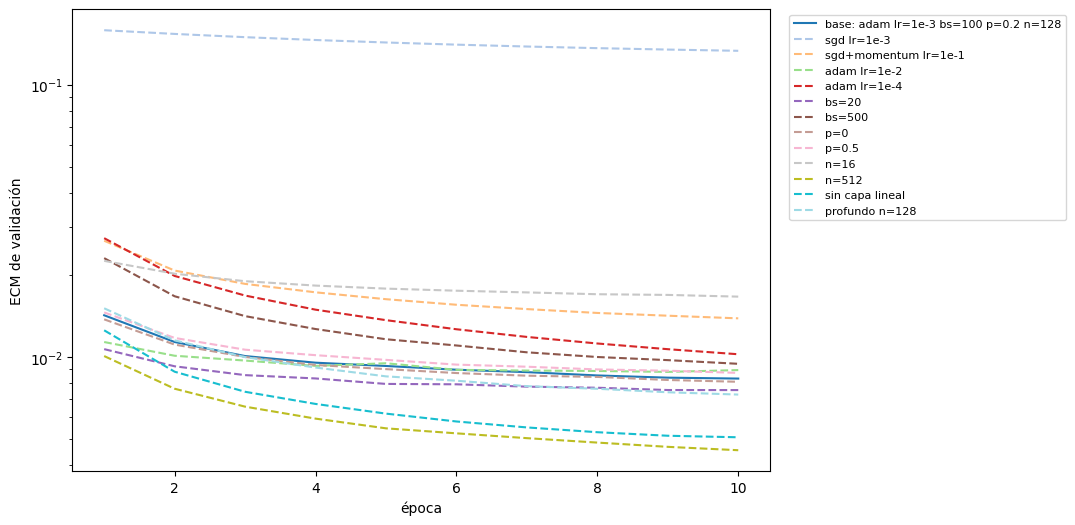

sin capa lineal


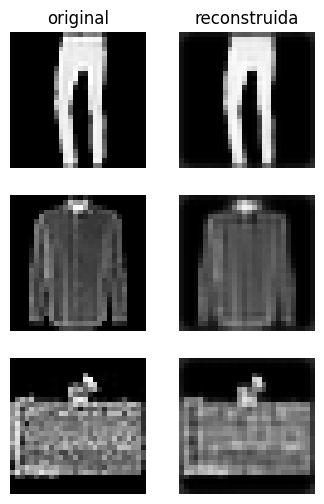

profundo n=128


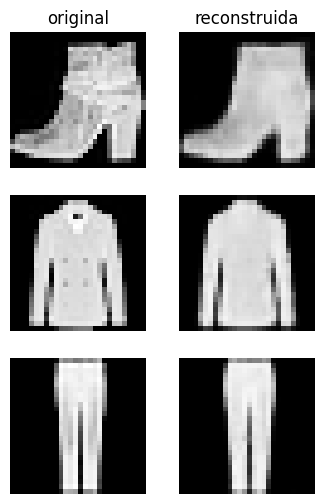

n=16


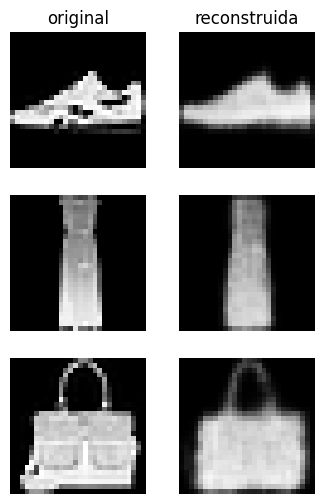

In [25]:
plt.figure(figsize=(9, 6))
colors = plt.cm.tab20(np.linspace(0, 1, len(results)))
for (name, (_, h)), c in zip(results.items(), colors):
    plt.plot(range(1, len(h["valid"])+1), h["valid"], label=name, c=c, linestyle='-' if name.startswith("base") else '--')
plt.xlabel('época')
plt.ylabel('ECM de validación')
plt.yscale('log')
plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()


# Reconstrucciones del autoencoder sin cuello de botella y del profundo
for name in ["sin capa lineal", "profundo n=128", "n=16"]:
    print(name)
    plot_reconstructions(results[name][0], valid_set, n=3)


**Respuesta 5.11)**

Resultados (ECM de validación luego de 10 épocas; el modelo base tiene $\approx 0.0081$):

| experimento | ECM valid. | comentario |
| :--- | :---: | :--- |
| base (Adam, $\text{lr}=10^{-3}$, $\text{bs}=100$, $p=0.2$, $n=128$) | 0.0081 | |
| SGD, $\text{lr}=10^{-3}$ | 0.133 | prácticamente no aprende en 10 épocas |
| SGD + momentum $0.9$, $\text{lr}=10^{-1}$ | 0.0138 | aprende, pero más lento que Adam |
| Adam, $\text{lr}=10^{-2}$ | 0.0087 | baja rápido al principio pero se estanca |
| Adam, $\text{lr}=10^{-4}$ | 0.0103 | demasiado lento |
| $\text{bs}=20$ | 0.0075 | mejor por época, pero hace 5 veces más actualizaciones y tarda más |
| $\text{bs}=500$ | 0.0094 | 5 veces menos actualizaciones por época |
| $p=0$ | 0.0081 | igual que $p=0.2$ |
| $p=0.5$ | 0.0085 | algo peor |
| $n=16$ | 0.0169 | mucha compresión, reconstrucción pobre |
| $n=512$ | 0.0045 | poca compresión, buena reconstrucción |
| sin capa lineal | 0.0051 | ¡sólo 737 parámetros! pero no comprime (ver abajo) |
| profundo, $n=128$ | 0.0074 | mejor que el base con $\sim 60\%$ de los parámetros |



Conclusiones:

* **Optimizador y learning rate**: Adam con $\text{lr} \sim 10^{-3}$ es claramente la mejor opción. SGD sin momentum y con $\text{lr}=10^{-3}$ es órdenes de magnitud más lento; con momentum y un $\text{lr}$ grande mejora mucho, pero sigue detrás de Adam. Con Adam, $\text{lr}=10^{-2}$ es demasiado grande (se estanca en un valor más alto) y $\text{lr}=10^{-4}$ demasiado chico.
* **Tamaño de lote**: a igual número de épocas, los lotes chicos ganan porque hacen más actualizaciones de los parámetros, pero cada época es más lenta (sobre todo en GPU, donde los lotes grandes se paralelizan mejor). Una comparación justa debería hacerse a igual número de actualizaciones o a igual tiempo de cómputo. Valores entre 50 y 100 son un buen compromiso.
* **Dropout**: como no hay sobreajuste (ver 5.9), regularizar no ayuda: $p = 0$ y $p = 0.2$ dan lo mismo y $p = 0.5$ es peor. Pasaría a ser útil con modelos más grandes o con menos datos.
* **Dimensión del código latente $n$**: es el hiperparámetro más importante. Controla el compromiso entre **compresión y calidad de la reconstrucción**: el ECM baja de $0.017$ ($n = 16$) a $0.0045$ ($n = 512$). Su valor "conveniente" depende del uso que se le quiera dar al código (comprimir, reducir dimensionalidad, eliminar ruido, etc.), no sólo del ECM.
* **Sin capa lineal**: reconstruye mejor que el modelo base con sólo 737 parámetros, pero eso es engañoso. Sin el cuello de botella, la representación intermedia tiene dimensión $16 \times 13 \times 13 = 2704 > 784$: la red **no comprime** y le alcanza con aprender un filtro local cercano a la identidad. Un autoencoder sirve en tanto la representación intermedia sea más chica (o esté restringida de alguna otra forma) que la entrada. Por lo tanto, el ECM por sí solo no basta para elegir la arquitectura.
* **Arquitectura más profunda**: dos convoluciones con stride 2 (en vez de una convolución más *max-pooling*) y dos convoluciones transpuestas simétricas reconstruyen mejor que el modelo base, con el mismo $n = 128$ y $\sim 60\%$ de los parámetros ($4.1 \times 10^5$ vs $7.0 \times 10^5$). Las capas convolucionales extraen rasgos más útiles antes de comprimir, y la capa lineal es más chica porque mapea
* **Arquitectura más profunda**: dos convoluciones con stride 2 (en vez de una convolución más *max-pooling*) y dos convoluciones transpuestas simétricas reconstruyen mejor que el modelo base, con el mismo $n = 128$ y $\sim 60\%$ de los parámetros ($4.1 \times 10^5$ vs $7.0 \times 10^5$). Las capas convolucionales extraen rasgos más útiles antes de comprimir, y la capa lineal es más chica porque mapea $32 \times 7 \times 7 = 1568$ (en vez de $2704$) a $n$.

En resumen, conviene usar Adam con $\text{lr} \sim 10^{-3}$, lotes de 50–100 ejemplos, poco o nada de dropout, una arquitectura convolucional más profunda y simétrica, y elegir $n$ según el compromiso compresión/reconstrucción deseado.
